# Fase 1 — Comprensión del problema y EDA inicial

**Proyecto:** Análisis de tarifas de Uber (Equipo 4 — Transporte)

Objetivos de este notebook:
1. Cargar el dataset original y conocer su estructura.
2. Evaluar la calidad de los datos (nulos, duplicados, valores fuera de rango).
3. Hacer una primera exploración de las variables que responde a las preguntas clave
   definidas en `docs/01_comprension_problema.md`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR, NYC_BOUNDS
from src.data_loader import anomaly_summary, load_raw_data, quality_report

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Carga del dataset

In [2]:
df = load_raw_data()
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 200,000 | Columnas: 8


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2015-05-07 19:52:06.0000003,7.5000,2015-05-07 19:52:06,-73.9998,40.7384,-73.9995,40.7232,1
1,2009-07-17 20:04:56.0000002,7.7000,2009-07-17 20:04:56,-73.9944,40.7282,-73.9947,40.7503,1
2,2009-08-24 21:45:00.00000061,12.9000,2009-08-24 21:45:00,-74.0050,40.7408,-73.9626,40.7726,1
3,2009-06-26 08:22:21.0000001,5.3000,2009-06-26 08:22:21,-73.9761,40.7908,-73.9653,40.8033,3
4,2014-08-28 17:47:00.000000188,16.0000,2014-08-28 17:47:00,-73.9250,40.7441,-73.9731,40.7612,5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   key                200000 non-null  str           
 1   fare_amount        200000 non-null  float64       
 2   pickup_datetime    200000 non-null  datetime64[us]
 3   pickup_longitude   200000 non-null  float64       
 4   pickup_latitude    200000 non-null  float64       
 5   dropoff_longitude  199999 non-null  float64       
 6   dropoff_latitude   199999 non-null  float64       
 7   passenger_count    200000 non-null  int64         
dtypes: datetime64[us](1), float64(5), int64(1), str(1)
memory usage: 12.2 MB


## 2. Calidad de los datos

In [4]:
quality_report(df)

,tipo,nulos,pct_nulos,unicos,minimo,maximo
key,str,0,0.0000,200000,NaN,NaN
fare_amount,float64,0,0.0000,1244,-52.0000,499.0000
pickup_datetime,datetime64[us],0,0.0000,196629,NaN,NaN
pickup_longitude,float64,0,0.0000,71066,"-1,340.6484",57.4185
pickup_latitude,float64,0,0.0000,83835,-74.0155,"1,644.4215"
dropoff_longitude,float64,1,0.0000,76894,"-3,356.6663","1,153.5726"
dropoff_latitude,float64,1,0.0000,90585,-881.9855,872.6976
passenger_count,int64,0,0.0000,8,0.0000,208.0000


In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
fare_amount,"200,000.0000",11.3600,-52.0000,6.0000,8.5000,12.5000,499.0000,9.9018
pickup_datetime,200000,2012-03-22 15:02:18.433114,2009-01-01 01:15:22,2010-08-25 08:20:16,2012-03-21 20:44:29.500000,2013-10-19 02:14:16.500000,2015-06-30 23:40:39,NaN
pickup_longitude,"200,000.0000",-72.5276,"-1,340.6484",-73.9921,-73.9818,-73.9672,57.4185,11.4378
pickup_latitude,"200,000.0000",39.9359,-74.0155,40.7348,40.7526,40.7672,"1,644.4215",7.7205
dropoff_longitude,"199,999.0000",-72.5253,"-3,356.6663",-73.9914,-73.9801,-73.9637,"1,153.5726",13.1174
dropoff_latitude,"199,999.0000",39.9239,-881.9855,40.7338,40.7530,40.7680,872.6976,6.7948
passenger_count,"200,000.0000",1.6845,0.0000,1.0000,1.0000,2.0000,208.0000,1.3860


### Registros con valores fuera de rango lógico

Se consideran anómalos: tarifas no positivas o extremas, viajes sin pasajeros o con más de 6,
coordenadas fuera del área metropolitana de Nueva York y viajes con origen igual a destino.

In [6]:
anomaly_summary(df, NYC_BOUNDS)

,registros,pct
Tarifa <= 0,22,0.0100
Tarifa > 250 USD,3,0.0000
Pasajeros = 0,709,0.3500
Pasajeros > 6,1,0.0000
Coordenadas fuera de NYC,4404,2.2000
Origen igual a destino,5632,2.8200
Registros duplicados (key),0,0.0000


## 3. Exploración inicial

Para la exploración visual se usa un filtro básico (tarifa entre 0 y 100 USD) que evita que los valores
extremos oculten la forma de las distribuciones. La limpieza formal se realiza en la Fase 3.

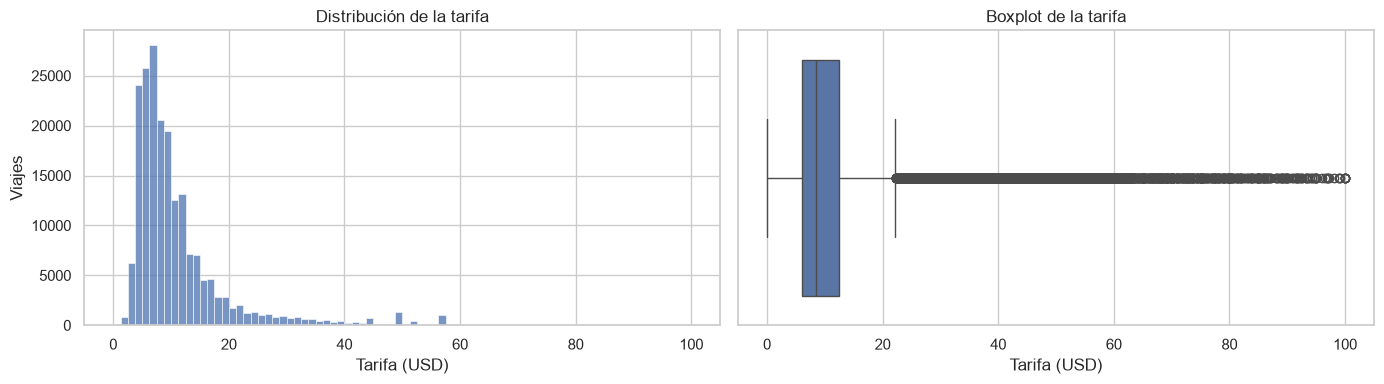

In [7]:
eda = df[(df["fare_amount"] > 0) & (df["fare_amount"] <= 100)].copy()
eda["anio"] = eda["pickup_datetime"].dt.year
eda["hora"] = eda["pickup_datetime"].dt.hour
eda["dia_semana"] = eda["pickup_datetime"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(eda["fare_amount"], bins=80, ax=axes[0])
axes[0].set(title="Distribución de la tarifa", xlabel="Tarifa (USD)", ylabel="Viajes")
sns.boxplot(x=eda["fare_amount"], ax=axes[1])
axes[1].set(title="Boxplot de la tarifa", xlabel="Tarifa (USD)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_distribucion_tarifa.png", dpi=120)
plt.show()

La tarifa presenta una **asimetría positiva marcada**: la mayoría de los viajes cuestan menos de 20 USD,
con una cola larga de viajes costosos. Esto anticipa que las pruebas paramétricas basadas en normalidad
podrían no ser adecuadas.

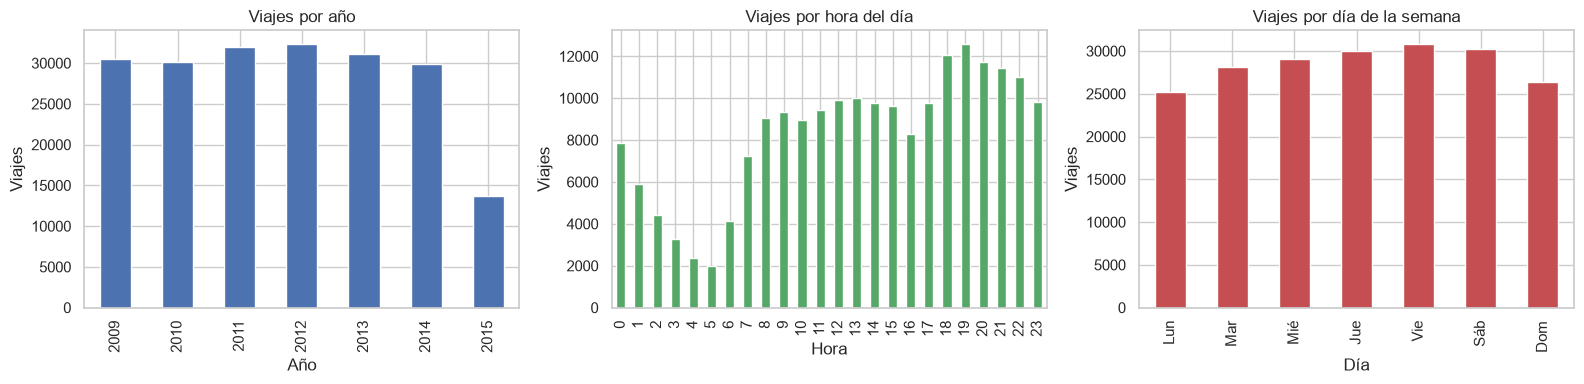

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
eda["anio"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set(title="Viajes por año", xlabel="Año", ylabel="Viajes")
eda["hora"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set(title="Viajes por hora del día", xlabel="Hora", ylabel="Viajes")
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
eda["dia_semana"].value_counts().sort_index().set_axis(dias).plot(
    kind="bar", ax=axes[2], color="#C44E52"
)
axes[2].set(title="Viajes por día de la semana", xlabel="Día", ylabel="Viajes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_demanda_temporal.png", dpi=120)
plt.show()

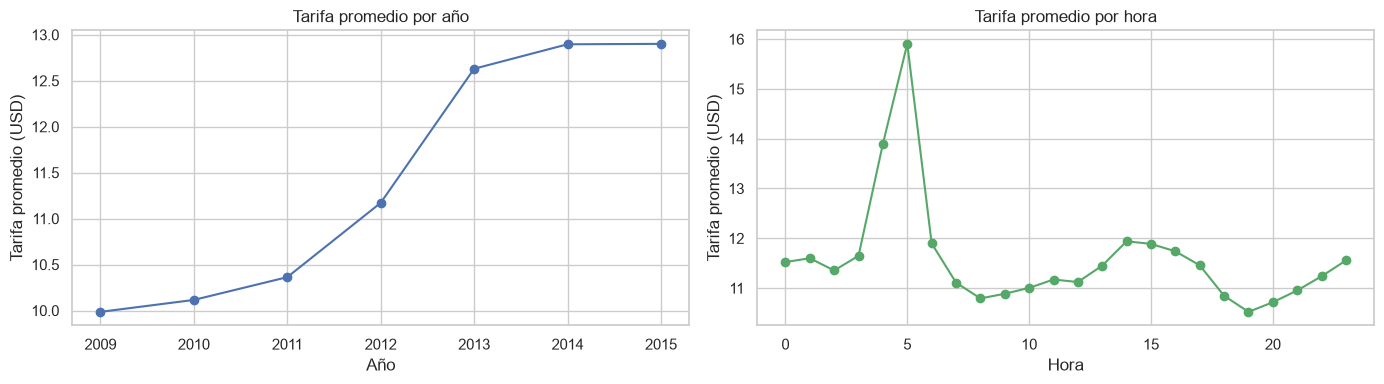

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
eda.groupby("anio")["fare_amount"].mean().plot(marker="o", ax=axes[0])
axes[0].set(title="Tarifa promedio por año", xlabel="Año", ylabel="Tarifa promedio (USD)")
eda.groupby("hora")["fare_amount"].mean().plot(marker="o", ax=axes[1], color="#55A868")
axes[1].set(title="Tarifa promedio por hora", xlabel="Hora", ylabel="Tarifa promedio (USD)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_tarifa_temporal.png", dpi=120)
plt.show()

In [10]:
eda["passenger_count"].value_counts().sort_index().to_frame("viajes")

,viajes
passenger_count,
0,709
1,138349
2,29412
3,8875
4,4275
5,14003
6,4270
208,1


## 4. Conclusiones del EDA inicial

- El dataset tiene ~200.000 viajes y una cantidad muy baja de nulos, pero **sí contiene valores inválidos**
  (tarifas no positivas, coordenadas en cero o fuera de la ciudad, pasajeros en 0 o atípicos) que deben
  tratarse en la Fase 3.
- No existe una variable de distancia: se calculará a partir de las coordenadas.
- La tarifa es asimétrica a la derecha, por lo que se privilegiarán **pruebas no paramétricas**.
- Se observan patrones temporales en la demanda (horas y días) y en la tarifa promedio por año,
  lo que da pie a las hipótesis de la Fase 2.
- **Zona horaria:** aunque `pickup_datetime` dice "UTC", la demanda por hora sigue el patrón local de los
  taxis de Nueva York (mínimo a las 5 h, hora pico de 7 a 9 h, caída a las 16 h por el cambio de turno y
  máximo a las 19 h) y el rango de fechas va exactamente del 01-01-2009 al 30-06-2015. Por eso se concluye
  que las fechas ya están en hora local y **no se convierten**. Convertirlas desplazaría todo 4-5 horas.